# Experimental binder classification: leave-one-target-out results

Compare GraPPI, the ESM-only baseline, and the two AF3 features from [Figure 3B of the study](https://www.biorxiv.org/content/10.1101/2025.08.14.670059v2.full). Select the **PPI** Python kernel, then choose **Run All**. This notebook reads the completed training exports and deposited feature scores; it does not train models or modify results. Change the paths or `TARGET_TO_PLOT` in the next cell if needed.

`AF3_ipSAE` and `AF3_interaction` are **recomputed from the deposited CSV on the same samples as the available model runs**; they are not values copied from the figure. The interaction is ranked as `-af3_ipSAE_min * af3_rosetta_interface_dG_SASA_ratio` so higher scores indicate stronger predicted binding, matching the paper's lower-is-better raw product.

**Dataset discrepancy:** the paper reports 3,766 designs and 436 binders. Its checksum-verified Zenodo CSV contains 3,676 rows, of which 3,669 are labeled and 394 are binders. The reason is not yet known, so recomputed results may differ from published figures.

**Interpretation:** AP is `average_precision_score`, not trapezoidal PR area. Positive prevalence is the horizontal reference for an uninformative PR curve; finite-sample expected random-ranking AP can differ, especially with few positives. Lift is AP / prevalence. The held-out target also selected the GraPPI/ESM best epoch, so those are potentially optimistic validation scores, **not independent test estimates**. Pooled predictions from different fold models require cross-target score comparability. AF3 features use re-predicted structures; GraPPI used input structures.

In [ ]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_curve

# Works when the notebook starts in either the repository or this folder.
cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents)
                  if (p / 'exp_target_retraining' / 'config_exp_target_wbce.yaml').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Start the notebook from GraPPI or set REPO_ROOT to the repository path.')
sys.path.insert(0, str(REPO_ROOT / 'exp_target_retraining'))
import loto_results
importlib.reload(loto_results)
from loto_results import (aggregate_table, check_comparable, comparison_table,
                          load_af3_features, load_run, missing_run_files, read_dataset_labels)

# Edit these paths if you used --output-dir or a different dataset location.
DATA_ROOT = REPO_ROOT.parent / 'GraPPI_data'
LABELS_FILE = DATA_ROOT / 'exp_binder_data' / 'labels.csv'
PAPER_DATA_FILE = DATA_ROOT / 'exp_binder_data' / 'final_dataset.csv'
TRAINED_ROOT = DATA_ROOT / 'trained_data_ssl_finetune'
RUN_PATHS = {
    'GraPPI': (TRAINED_ROOT / '2layers_10hdim_esm_exp_target_loto_wbce', 'grappi'),
    'ESM': (TRAINED_ROOT / 'esm1280_exp_target_loto_wbce', 'esm'),
}
METHOD_LABELS = {'GraPPI': 'GraPPI', 'ESM': 'ESM', 'AF3_ipSAE': 'AF3 ipSAE_min',
                 'AF3_interaction': 'AF3 interaction'}

pd.set_option('display.max_columns', None)

## Run availability

Each run writes its final CSV/JSON exports after all folds finish. Checkpoints may exist while a fold is still training, so their count is **not** a completed-fold count. If a run is restarted in the same folder, old exports may remain until it finishes; check their timestamps. AF3 scores are recomputed from the deposited CSV; mismatched samples, labels, or missing feature values cause an error rather than a partial comparison.

In [2]:
labels = read_dataset_labels(LABELS_FILE)
runs = {}
status_rows = []
for model, (directory, mode) in RUN_PATHS.items():
    missing = missing_run_files(directory)
    summary_path = directory / 'exp_target_loto_summary.json'
    status_rows.append({
        'model': model,
        'status': 'waiting for final exports' if missing else 'final exports present',
        'checkpoint_files': len(list(directory.glob('*_exp_target_loto_*_best.pt'))),
        'missing_files': ', '.join(missing) if missing else '',
        'summary_modified': pd.Timestamp.fromtimestamp(summary_path.stat().st_mtime) if summary_path.is_file() else None,
        'directory': str(directory),
    })
    if not missing:
        runs[model] = load_run(directory, mode, labels)
check_comparable(runs)
paper_features = {}
if PAPER_DATA_FILE.is_file():
    paper_features = load_af3_features(PAPER_DATA_FILE, labels, runs)
    feature_status = 'recomputed on model cohort' if runs else 'recomputed on labeled dataset (no model ready)'
else:
    feature_status = 'source CSV missing; AF3 features not available'
status_rows.append({
    'model': 'AF3 paper features', 'status': feature_status,
    'checkpoint_files': None, 'missing_files': '' if paper_features else str(PAPER_DATA_FILE),
    'summary_modified': None, 'directory': str(PAPER_DATA_FILE),
})
display(pd.DataFrame(status_rows))
if not runs:
    display(Markdown('**No final model exports yet.** AF3 features, if available, use the labeled dataset; rerun all cells after training completes.'))
elif len(runs) < len(RUN_PATHS):
    display(Markdown('**Only one run is ready.** Its results are shown below; rerun all cells when the other run completes.'))

,model,status,checkpoint_files,missing_files,summary_modified,directory
0,GraPPI,final exports present,15.0,,2026-11-04 11:06:32.320885,/mnt/poisson/data/zhisong/GraPPI_data/trained_...
1,ESM,final exports present,15.0,,2026-11-04 11:10:31.164836,/mnt/poisson/data/zhisong/GraPPI_data/trained_...
2,AF3 paper features,recomputed on model cohort,NaN,,NaT,/mnt/poisson/data/zhisong/GraPPI_data/exp_bind...


## Per-target comparison

When results are available, `n`, `n_pos`, `n_neg`, and `prevalence` refer to the **evaluated** samples. `dataset_n` is the labeled dataset total; `n_excluded` is the difference. Model AP and AUROC use saved probabilities; AF3 metrics use deposited ranking scores, not probabilities. Lift uses evaluated-target prevalence. The first table shows AP and lift; the second shows AUROC and selected model epochs. The difference columns are GraPPI minus ESM. Targets with very few positives have unstable AP estimates.

In [3]:
per_target = comparison_table(labels, runs, paper_features)
if runs or paper_features:
    first_columns = ['target_id', 'dataset_n', 'n', 'n_excluded', 'n_pos', 'n_neg', 'prevalence']
    methods = [*runs, *paper_features]
    ap_columns = [column for name in methods for column in (f'{name}_AP', f'{name}_lift')]
    roc_columns = [f'{name}_AUROC' for name in methods]
    ap_columns += [c for c in ['AP_difference'] if c in per_target]
    roc_columns += [c for c in ['AUROC_difference', 'GraPPI_best_epoch', 'ESM_best_epoch'] if c in per_target]
    display(Markdown('#### Average precision and lift'))
    display(per_target[first_columns + ap_columns].round(4))
    display(Markdown('#### AUROC and selected model epochs'))
    display(per_target[['target_id'] + roc_columns].round(4))
    if per_target['n_excluded'].sum():
        print(f"Warning: {int(per_target['n_excluded'].sum())} labeled samples were not evaluated; see n_excluded.")
else:
    display(per_target.round(4))

#### Average precision and lift

,target_id,dataset_n,n,n_excluded,n_pos,n_neg,prevalence,GraPPI_AP,GraPPI_lift,ESM_AP,ESM_lift,AF3_ipSAE_AP,AF3_ipSAE_lift,AF3_interaction_AP,AF3_interaction_lift,AP_difference
0,FGFR2,2123,2123,0,193,1930,0.0909,0.1470,1.6165,0.1473,1.6203,0.3812,4.1935,0.4082,4.4899,-0.0003
1,EGFR,434,434,0,28,406,0.0645,0.1024,1.5868,0.0810,1.2563,0.2454,3.8040,0.3634,5.6327,0.0213
2,IL7Ra,171,171,0,38,133,0.2222,0.3248,1.4614,0.3089,1.3900,0.5274,2.3734,0.5197,2.3387,0.0159
3,TrkA,128,128,0,9,119,0.0703,0.1748,2.4865,0.0934,1.3284,0.3027,4.3049,0.2446,3.4785,0.0814
4,InsulinR,117,117,0,20,97,0.1709,0.3735,2.1848,0.2668,1.5609,0.4288,2.5087,0.3897,2.2800,0.1066
5,SARS_CoV2_RBD,99,99,0,9,90,0.0909,0.3674,4.0412,0.2549,2.8041,0.6915,7.6070,0.5844,6.4284,0.1125
6,VirB8,99,99,0,9,90,0.0909,0.1926,2.1185,0.2662,2.9281,0.5399,5.9392,0.5574,6.1311,-0.0736
7,pMHC_SILSY1,96,96,0,2,94,0.0208,0.0330,1.5844,0.0515,2.4715,0.1048,5.0286,0.0634,3.0409,-0.0185
8,Mdm2,96,96,0,55,41,0.5729,0.6936,1.2107,0.7033,1.2276,0.6489,1.1326,0.6348,1.1079,-0.0097
9,Pdl1,95,95,0,12,83,0.1263,0.2982,2.3608,0.2087,1.6524,0.5431,4.2999,0.6508,5.1518,0.0895


#### AUROC and selected model epochs

,target_id,GraPPI_AUROC,ESM_AUROC,AF3_ipSAE_AUROC,AF3_interaction_AUROC,AUROC_difference,GraPPI_best_epoch,ESM_best_epoch
0,FGFR2,0.6576,0.6219,0.7525,0.7482,0.0357,4,4
1,EGFR,0.6263,0.4960,0.8004,0.8040,0.1304,12,8
2,IL7Ra,0.6057,0.5689,0.8021,0.8178,0.0368,32,8
3,TrkA,0.6704,0.5929,0.7540,0.7264,0.0775,1,1
4,InsulinR,0.7216,0.6325,0.7402,0.7845,0.0892,4,1
5,SARS_CoV2_RBD,0.7284,0.5395,0.8469,0.8444,0.1889,33,40
6,VirB8,0.4506,0.7086,0.8148,0.8173,-0.2580,1,18
7,pMHC_SILSY1,0.5426,0.7128,0.8245,0.7713,-0.1702,1,1
8,Mdm2,0.5667,0.5743,0.5734,0.5805,-0.0075,18,6
9,Pdl1,0.6044,0.5161,0.8760,0.8825,0.0884,15,17


## Across-target summary

Median and interquartile range (Q25–Q75) give each target equal weight, in the style of Figure 3D. The AF3 rows are the Figure 3B features recomputed on the matched cohort; Figure 3D selected features by median across targets, which need not be the same features. The `_n_targets` columns show how many targets have both classes. Pooled AP/AUROC concatenate scores across targets and are not interchangeable with the target-level median; pooled model scores come from separately trained folds.

For context, the [paper's Figure 4](https://www.biorxiv.org/content/10.1101/2025.08.14.670059v2.full) separately reports these values. They use **different features or a different model and the paper's stated cohort**, not the matched-cohort AF3 rows below:

| Published method | Median target AP | IQR |
|---|---:|---:|
| AF3 LIS × input interface shape complementarity | 0.58 | 0.33–0.66 |
| AF3 individual-feature logistic model | 0.57 | 0.40–0.66 |

The paper's logistic model used nested target-group cross-validation, unlike the best-epoch selection on each held-out target used for GraPPI and ESM.

In [4]:
aggregates = aggregate_table(runs, paper_features)
if aggregates.empty:
    print('Summary metrics will appear when a model run or the paper features are available.')
else:
    display(aggregates.set_index('model').round(4).astype(object).T)

model,GraPPI,ESM,AF3_ipSAE,AF3_interaction
n_samples,3669,3669,3669,3669
n_targets,15,15,15,15
AP_n_targets,15,15,15,15
AP_median,0.3098,0.2662,0.5274,0.5197
AP_q25,0.1609,0.178,0.342,0.3766
AP_q75,0.3646,0.5852,0.6702,0.6428
AP_iqr,0.2038,0.4072,0.3282,0.2662
AUROC_n_targets,15,15,15,15
AUROC_median,0.6704,0.6325,0.8148,0.8173
AUROC_q25,0.605,0.5716,0.7532,0.7597


## Per-target AP and AUROC

Target labels show positive / evaluated sample counts. The black marks are the target prevalence reference; the dashed AUROC line is 0.5. AF3 points are recomputed deposited-feature scores.

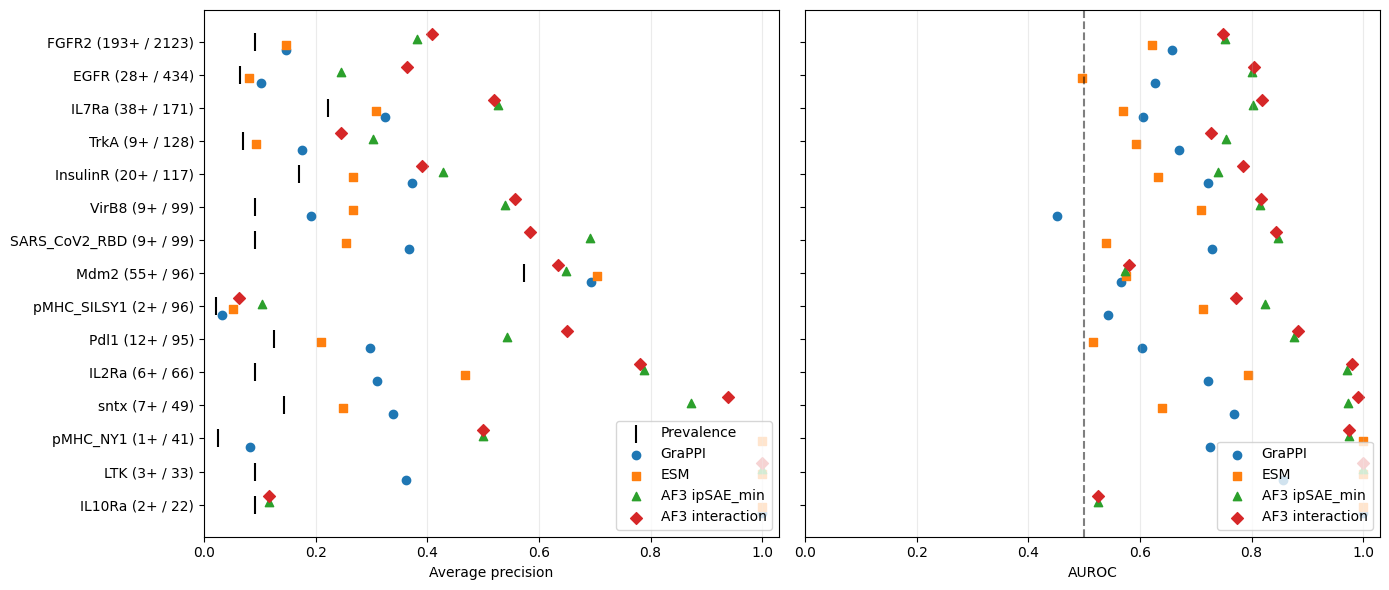

In [5]:
if not runs and not paper_features:
    print('Plots will appear when a model run or the paper features are available.')
else:
    chart = per_target.loc[per_target['n'] > 0].sort_values('dataset_n')
    y = np.arange(len(chart))
    fig, axes = plt.subplots(1, 2, figsize=(14, max(5, len(chart) * 0.40)), sharey=True)
    axes[0].scatter(chart['prevalence'], y, marker='|', s=150, color='black', label='Prevalence')
    markers = {'GraPPI': ('o', 'tab:blue'), 'ESM': ('s', 'tab:orange'),
               'AF3_ipSAE': ('^', 'tab:green'), 'AF3_interaction': ('D', 'tab:red')}
    methods = [*runs, *paper_features]
    offsets = np.linspace(-0.25, 0.25, len(methods)) if len(methods) > 1 else [0]
    for offset, method in zip(offsets, methods):
        marker, color = markers[method]
        axes[0].scatter(chart[f'{method}_AP'], y + offset, marker=marker, color=color, label=METHOD_LABELS[method])
        axes[1].scatter(chart[f'{method}_AUROC'], y + offset, marker=marker, color=color, label=METHOD_LABELS[method])
    axes[1].axvline(0.5, color='black', linestyle='--', alpha=0.5)
    axes[0].set_yticks(y, [f'{r.target_id} ({r.n_pos}+ / {r.n})' for r in chart.itertuples()])
    for ax, title in zip(axes, ['Average precision', 'AUROC']):
        ax.set(xlim=(0, 1.03), xlabel=title)
        ax.grid(axis='x', alpha=0.25)
        ax.legend(loc='lower right')
    fig.tight_layout()
    plt.show()

## Precision–recall curve for one target

Change `TARGET_TO_PLOT` in the setup cell and rerun the notebook. GraPPI and ESM curves use saved per-sample probabilities; AF3 curves use deposited feature rankings, which are not probabilities.

In [7]:
TARGET_TO_PLOT = 'IL10Ra'  # Change to any target_id e.g. IL10Ra

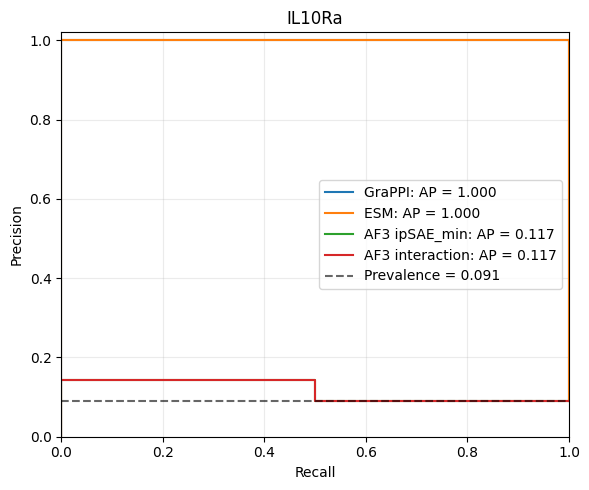

In [8]:
if not runs and not paper_features:
    print('Precision–recall curves will appear when a model run or the paper features are available.')
else:
    methods = {name: (run.scores, run.per_target, 'prob') for name, run in runs.items()}
    methods.update({name: (feature.scores, feature.per_target, 'score')
                    for name, feature in paper_features.items()})
    target_data = {name: scores.loc[scores['target_id'] == TARGET_TO_PLOT]
                   for name, (scores, _, _) in methods.items()}
    if any(part.empty for part in target_data.values()):
        print(f'{TARGET_TO_PLOT!r} is not present in every available method. Choose a target from the table.')
    elif next(iter(target_data.values()))['label'].nunique() != 2:
        print(f'{TARGET_TO_PLOT!r} has only one class; a two-class PR comparison is not available.')
    else:
        fig, ax = plt.subplots(figsize=(6, 5))
        for method, part in target_data.items():
            _, method_targets, score_column = methods[method]
            precision, recall, _ = precision_recall_curve(part['label'], part[score_column])
            ap = method_targets.set_index('target_id').loc[TARGET_TO_PLOT, 'ap']
            ax.step(recall, precision, where='post', label=f'{METHOD_LABELS[method]}: AP = {ap:.3f}')
        prevalence = next(iter(target_data.values()))['label'].mean()
        ax.axhline(prevalence, linestyle='--', color='black', alpha=0.6, label=f'Prevalence = {prevalence:.3f}')
        ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall', ylabel='Precision', title=TARGET_TO_PLOT)
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        plt.show()